In [67]:
import pandas as pd
import numpy as np

In [68]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [69]:
df = pd.read_parquet('/content/drive/MyDrive/CSC1181/Combined.parquet')
df.head()

,image_url,creator,created_date,last_modified_date,completeness,nutriscore_grade,ingredients_text,allergens,additives_n,additives_en,...,categories_en,labels_en,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,unique_scans_n,main_category_en,has_organic_label
0,https://images.openfoodfacts.org/images/produc...,beniben,2016-01-12,2025-03-05,0.8875,D,"mûre bio 50% (fruit 27%, purée 23%) sucre de c...","eggs, gluten, milk, nuts",1.0,E440 - Pectins,...,plant-based foods and beverages,Made in France,117.585012,2.576112,0.5,23.6,3.04,2.0,Dried fruits,0.0
1,https://images.openfoodfacts.org/images/produc...,beniben,2016-01-12,2024-04-10,0.8875,E,"Farine de _blé_, fourrage lait et caramel 17% ...","eggs, gluten, milk, soybeans",8.0,"E202 - Potassium sorbate,E322 - Lecithins,E422...",...,sandwiches,"Organic,Vegetarian,EU Organic,Vegan,DE-ÖKO-006...",189.700000,10.100000,2.6,24.7,2.70,1.0,it:obesita,1.0
2,https://images.openfoodfacts.org/images/produc...,kiliweb,2022-06-03,2025-04-29,0.7000,C,"Water, Mushroom (20%), Fortified Wheat Flour (...",sulphur-dioxide-and-sulphites,7.0,"E160a - Carotene,E160ai - Beta-carotene,E160c ...",...,snacks,None,413.000000,21.000000,8.4,56.0,30.00,2.0,Powder-peanut-butter,0.0
3,https://images.openfoodfacts.org/images/produc...,openfoodfacts-contributors,2019-05-28,2024-04-10,0.7875,E,"Sucre, œufs frais (34%), farine de blé, sirop ...","eggs, gluten",3.0,"E336 - Potassium tartrates,E415 - Xanthan gum,...",...,snacks,None,413.000000,21.000000,8.4,56.0,30.00,1.0,Chocolate madeleines,0.0
4,https://images.openfoodfacts.org/images/produc...,kiliweb,2022-04-22,2024-11-12,0.7875,E,Amandes enrobées de chocolat au lait et poudre...,"gluten, milk, nuts",3.0,"E322 - Lecithins,E322i - Lecithin,E500 - Sodiu...",...,snacks,None,413.000000,21.000000,8.4,56.0,30.00,1.0,Long madeleines,0.0


In [70]:
df.isna().sum()

,0
image_url,1203421
creator,1203421
created_date,1203421
last_modified_date,1203421
completeness,1203421
nutriscore_grade,1203421
ingredients_text,1203421
allergens,1203421
additives_n,1203421
additives_en,1203421


In [71]:
df[['nova_group','nova_group_label']].head()

,nova_group,nova_group_label
0,<NA>,<NA>
1,<NA>,<NA>
2,<NA>,<NA>
3,4,Ultra-processed foods
4,4,Ultra-processed foods


In [72]:
total_rows = len(df) # Total rows after preliminary cleaning
missing_target_count = df["nova_group"].isna().sum()

print(f"Total merged rows: {total_rows}")
print(f"Rows missing target (nova_group): {missing_target_count} ({missing_target_count/total_rows*100:.2f}%)")

# Filtering to labeled subset for EDA and modeling
df_labeled = df[df["nova_group"].notna()].copy()
print(f"Labeled subset shape for training: {df_labeled.shape}")

Total merged rows: 1350179
Rows missing target (nova_group): 514272 (38.09%)
Labeled subset shape for training: (835907, 34)


In [73]:
# Check for exact row duplicates first
exact_dupes = df_labeled.duplicated().sum()
print(f"Exact duplicate rows: {exact_dupes:,}")

Exact duplicate rows: 17


In [74]:
df_labeled = df_labeled.drop_duplicates()

In [75]:
df_clean = df_labeled.copy()

In [76]:
nutrient_cols = [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g"
]

In [77]:
df_clean[nutrient_cols].describe()

,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g
count,835430.000000,835430.000000,835430.00000,835430.000000,835430.000000,835667.000000,835667.000000,835667.000000
mean,247.148849,13.295263,4.79128,26.708636,12.323206,2.219670,7.053619,1.165223
std,187.936413,17.340418,7.17916,24.857793,17.135436,3.190152,6.740412,104.990813
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,-0.454363
25%,98.700000,2.576112,0.50000,6.000000,1.754386,0.200000,2.310000,0.088185
50%,187.000000,7.700000,1.80000,17.798305,3.400000,1.600000,6.200000,0.390000
75%,413.000000,21.000000,8.40000,53.000000,21.666071,2.900000,8.000000,1.000000
max,900.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,92500.000000


In [78]:
df_clean.shape

(835890, 34)

In [79]:
df_clean = df_clean[df_clean['salt_100g'] <= 100]

In [100]:
base_features = [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g",
    "nova_group",
    "nova_group_label"
]

In [91]:
df_selected = df_clean.copy()

In [92]:
df_selected = df_selected[base_features]
df_selected.head()

,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,nova_group,nova_group_label
3,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
4,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,4,Ultra-processed foods
6,413.000000,21.000000,8.4,56.0,30.00,2.7,6.2,0.39,3,Processed foods
9,117.585012,2.576112,0.5,23.6,3.04,1.3,0.6,0.02,4,Ultra-processed foods
10,133.300000,7.700000,1.9,16.0,3.04,1.6,6.2,0.44,4,Ultra-processed foods


In [97]:
df_selected.isna().sum()

,0
energy-kcal_100g,0
fat_100g,0
saturated-fat_100g,0
carbohydrates_100g,0
sugars_100g,0
fiber_100g,0
proteins_100g,0
salt_100g,0
nova_group,0
nova_group_label,0


In [94]:
df_selected.shape

(835454, 10)

Too much hassle to deal with missing values

In [95]:
df_selected.dropna(inplace= True)

In [96]:
df_selected.describe()

,energy-kcal_100g,fat_100g,saturated-fat_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,nova_group
count,835053.000000,835053.000000,835053.000000,835053.00000,835053.000000,835053.000000,835053.000000,835053.000000,835053.0
mean,247.112300,13.293256,4.789886,26.70511,12.320136,2.216655,7.046848,0.782141,3.314381
std,187.924349,17.340413,7.177565,24.85691,17.132931,3.171612,6.713938,1.962373,1.036626
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,-0.454363,1.0
25%,98.700000,2.576112,0.500000,6.00000,1.754386,0.200000,2.318630,0.088185,3.0
50%,186.868687,7.700000,1.800000,17.70000,3.400000,1.600000,6.200000,0.390000,4.0
75%,413.000000,21.000000,8.400000,53.00000,21.600000,2.900000,8.000000,1.000000,4.0
max,900.000000,100.000000,100.000000,100.00000,100.000000,100.000000,100.000000,100.000000,4.0


EDA

In [98]:
# Target Class Counts & Percentages
nova_counts = df_selected["nova_group"].value_counts().sort_index()
nova_pcts = (df_selected["nova_group"].value_counts(normalize=True).sort_index() * 100).round(2)

target_summary = pd.DataFrame({"Count": nova_counts, "Percentage (%)": nova_pcts})
print("==========================================")
print(" TARGET CLASS DISTRIBUTION (NOVA GROUPS) ")
print("==========================================")
print(target_summary)

 TARGET CLASS DISTRIBUTION (NOVA GROUPS) 
             Count  Percentage (%)
nova_group                        
1           108097           12.94
2            34384            4.12
3           179469           21.49
4           513103           61.45


In [101]:
selected_features = [
    "energy-kcal_100g",
    "fat_100g",
    "saturated-fat_100g",
    "carbohydrates_100g",
    "sugars_100g",
    "fiber_100g",
    "proteins_100g",
    "salt_100g"
]

In [102]:
# Function to calculate IQR
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

# Grouped Median and IQR by NOVA group
median_stats = df_selected.groupby("nova_group")[selected_features].median().round(2)
iqr_stats = df_selected.groupby("nova_group")[selected_features].apply(lambda g: g.apply(iqr)).round(2)

print("\n==========================================")
print(" MEDIAN NUTRIENT VALUES BY NOVA GROUP ")
print("==========================================")
print(median_stats.T)


 MEDIAN NUTRIENT VALUES BY NOVA GROUP 
nova_group               1      2       3       4
energy-kcal_100g    117.59  732.3  164.40  196.00
fat_100g              2.58   81.0    7.70    8.10
saturated-fat_100g    0.50   10.0    1.70    2.30
carbohydrates_100g   12.14    0.6   12.14   23.60
sugars_100g           3.04    0.5    3.00    5.30
fiber_100g            2.40    0.0    1.60    1.60
proteins_100g         6.58    0.0    6.58    6.20
salt_100g             0.08    0.0    0.70    0.39


In [103]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# 1. Spearman Correlation Matrix
corr_matrix = df_selected[selected_features].corr(method="spearman").round(3)
print("\nTop Feature Correlations (|r| > 0.6):")
high_corr = corr_matrix.abs().unstack()
high_corr = high_corr[(high_corr > 0.6) & (high_corr < 1.0)].drop_duplicates()
print(high_corr)


Top Feature Correlations (|r| > 0.6):
energy-kcal_100g    fat_100g              0.776
                    saturated-fat_100g    0.693
fat_100g            saturated-fat_100g    0.917
carbohydrates_100g  sugars_100g           0.688
dtype: float64


/tmp/ipykernel_2868/159278525.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_2868/159278525.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


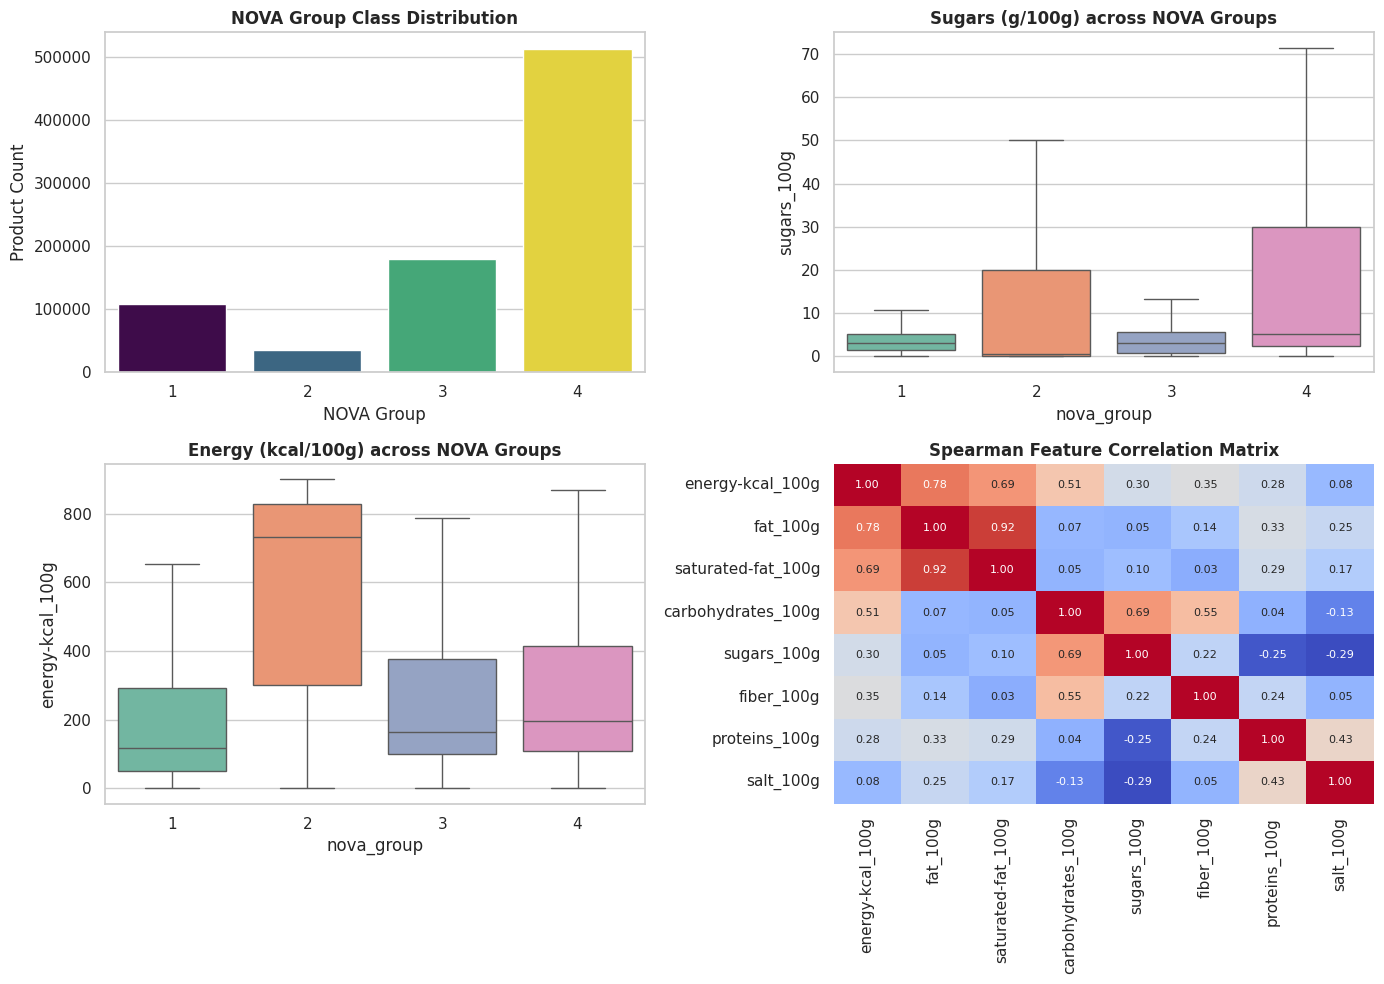

In [105]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# Create 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Target Class Distribution Barplot (Top-Left: axes[0, 0])
sns.barplot(
    x=nova_counts.index,
    y=nova_counts.values,
    ax=axes[0, 0],
    hue=nova_counts.index,
    palette="viridis",
    legend=False
)
axes[0, 0].set_title("NOVA Group Class Distribution", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("NOVA Group")
axes[0, 0].set_ylabel("Product Count")

# 2. Sugars Distribution by NOVA Group (Top-Right: axes[0, 1])
sns.boxplot(
    data=df_selected,
    x="nova_group",
    y="sugars_100g",
    ax=axes[0, 1],
    palette="Set2",
    showfliers=False
)
axes[0, 1].set_title("Sugars (g/100g) across NOVA Groups", fontsize=12, fontweight="bold")

# 3. Energy Distribution by NOVA Group (Bottom-Left: axes[1, 0])
sns.boxplot(
    data=df_selected,
    x="nova_group",
    y="energy-kcal_100g",
    ax=axes[1, 0],
    palette="Set2",
    showfliers=False
)
axes[1, 0].set_title("Energy (kcal/100g) across NOVA Groups", fontsize=12, fontweight="bold")

# 4. Correlation Heatmap (Bottom-Right: axes[1, 1])
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1, 1],
    cbar=False,
    annot_kws={"size": 8}
)
axes[1, 1].set_title("Spearman Feature Correlation Matrix", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.show()

In [106]:
df_selected.to_parquet('final.parquet')